In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
file_path = "../data/processed/india_vix_processed.csv"

df = pd.read_csv(file_path)

df["date"] = pd.to_datetime(df["date"])

df.head()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,...,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,vix_change,vix_change_pct,target_5d_volatility
0,2017-03-15,12.42,12.42,12.53,11.20,12.40,0,0.001613,0.001612,0.001613,...,14.3476,0.911010,0.665513,0.519895,-0.105187,-0.092768,-0.262032,0.020000,0.161294,0.415843
1,2017-03-16,11.91,11.91,12.42,11.34,12.42,0,-0.041063,-0.041930,-0.041063,...,14.2692,0.854666,0.684094,0.533534,-0.154119,-0.136957,-0.292335,-0.510000,-4.106282,0.379160
2,2017-03-17,11.85,11.85,12.11,10.39,11.91,0,-0.005038,-0.005050,-0.005038,...,14.1870,0.761545,0.684955,0.515888,-0.176511,-0.166080,-0.295900,-0.059999,-0.503774,0.387038
3,2017-03-20,12.02,12.02,12.31,11.44,11.85,0,0.014346,0.014244,0.014346,...,14.1096,0.853164,0.695894,0.513139,-0.138968,-0.124545,-0.285799,0.170000,1.434600,0.461619
4,2017-03-21,11.94,11.94,12.16,11.03,12.02,0,-0.006656,-0.006678,-0.006656,...,14.0474,0.331839,0.673655,0.509894,-0.037097,-0.110946,-0.290553,-0.080001,-0.665565,0.514888


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

Shape: (2319, 24)

Columns:
['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'vix_change', 'vix_change_pct', 'target_5d_volatility']

Missing Values:
0


In [4]:
features = [
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5",
    "volatility_10",
    "volatility_20",
    "momentum_5",
    "momentum_20",
    "drawdown"
]

features = [
    col for col in features
    if col in df.columns
]

target = "target_5d_volatility"

print("Features:")
print(features)

print("\nTarget:", target)

Features:
['daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'drawdown']

Target: target_5d_volatility


In [5]:
model_df = df[
    ["date"] + features + [target]
].copy()

model_df = model_df.dropna()

model_df = model_df.sort_values("date").reset_index(drop=True)

print("Model Dataset Shape:", model_df.shape)

model_df.head()

Model Dataset Shape: (2319, 11)


,date,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,drawdown,target_5d_volatility
0,2017-03-15,0.001613,0.001612,0.001613,0.107085,13.450,13.506,13.5970,14.3476,-0.262032,0.415843
1,2017-03-16,-0.041063,-0.041930,-0.041063,0.090680,13.016,13.339,13.5025,14.2692,-0.292335,0.379160
2,2017-03-17,-0.005038,-0.005050,-0.005038,0.145148,12.508,13.188,13.3845,14.1870,-0.295900,0.387038
3,2017-03-20,0.014346,0.014244,0.014346,0.072379,12.120,13.055,13.2990,14.1096,-0.285799,0.461619
4,2017-03-21,-0.006656,-0.006678,-0.006656,0.094640,12.028,12.885,13.2245,14.0474,-0.290553,0.514888


In [6]:
print(model_df[target].describe())

count    2319.000000
mean        0.716819
std         0.456364
min         0.032480
25%         0.435949
50%         0.608355
75%         0.847737
max         4.463848
Name: target_5d_volatility, dtype: float64


In [7]:
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training Rows:", len(train_df))
print("Testing Rows:", len(test_df))

Training Rows: 1855
Testing Rows: 464


In [8]:
print("Training Date Range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting Date Range:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training Date Range:
2017-03-15 00:00:00 to 2024-10-10 00:00:00

Testing Date Range:
2024-10-11 00:00:00 to 2026-08-31 00:00:00


In [9]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1855, 9)
X_test: (464, 9)


In [10]:
baseline_prediction = np.repeat(
    y_train.mean(),
    len(y_test)
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 0.35242415103508307
Baseline RMSE: 0.557209717429011


In [11]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 0.330057221632916
Linear Regression RMSE: 0.5355042021520381


In [12]:
coefficients = pd.DataFrame({
    "feature": features,
    "coefficient": linear_model.coef_
})

coefficients = coefficients.sort_values(
    by="coefficient",
    key=abs,
    ascending=False
)

coefficients

,feature,coefficient
0,daily_return,4.894156
1,log_return,-4.740645
3,price_range,0.860905
2,intraday_return,0.366278
8,drawdown,-0.110398
5,ma_10,-0.073165
4,ma_5,0.061459
6,ma_20,0.037001
7,ma_50,-0.019607


In [13]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 0.3321660123260138
Random Forest RMSE: 0.5329128864255029


In [14]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

results

,Model,MAE,RMSE
0,Baseline,0.352424,0.557210
1,Linear Regression,0.330057,0.535504
2,Random Forest,0.332166,0.532913


In [15]:
results_path = "../data/processed/india_vix_initial_model_results.csv"

results.to_csv(
    results_path,
    index=False
)

print("Model results saved successfully!")
print(results_path)

Model results saved successfully!
../data/processed/india_vix_initial_model_results.csv


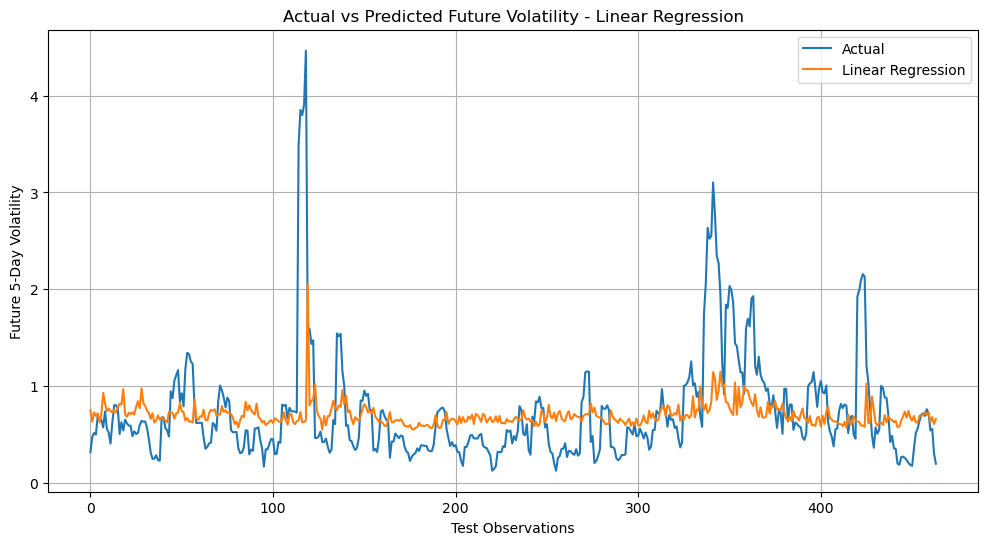

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    linear_predictions,
    label="Linear Regression"
)

plt.title("Actual vs Predicted Future Volatility - Linear Regression")
plt.xlabel("Test Observations")
plt.ylabel("Future 5-Day Volatility")
plt.legend()
plt.grid(True)

plt.show()

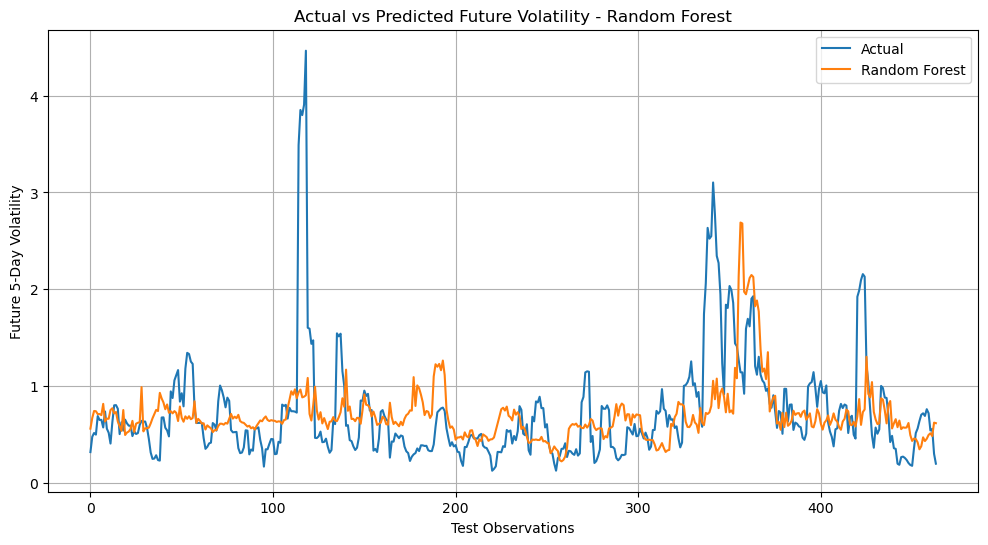

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    rf_predictions,
    label="Random Forest"
)

plt.title("Actual vs Predicted Future Volatility - Random Forest")
plt.xlabel("Test Observations")
plt.ylabel("Future 5-Day Volatility")
plt.legend()
plt.grid(True)

plt.show()

In [18]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
7,ma_50,0.232277
4,ma_5,0.156653
8,drawdown,0.144510
6,ma_20,0.135769
5,ma_10,0.132783
3,price_range,0.097542
2,intraday_return,0.036895
1,log_return,0.032420
0,daily_return,0.031152


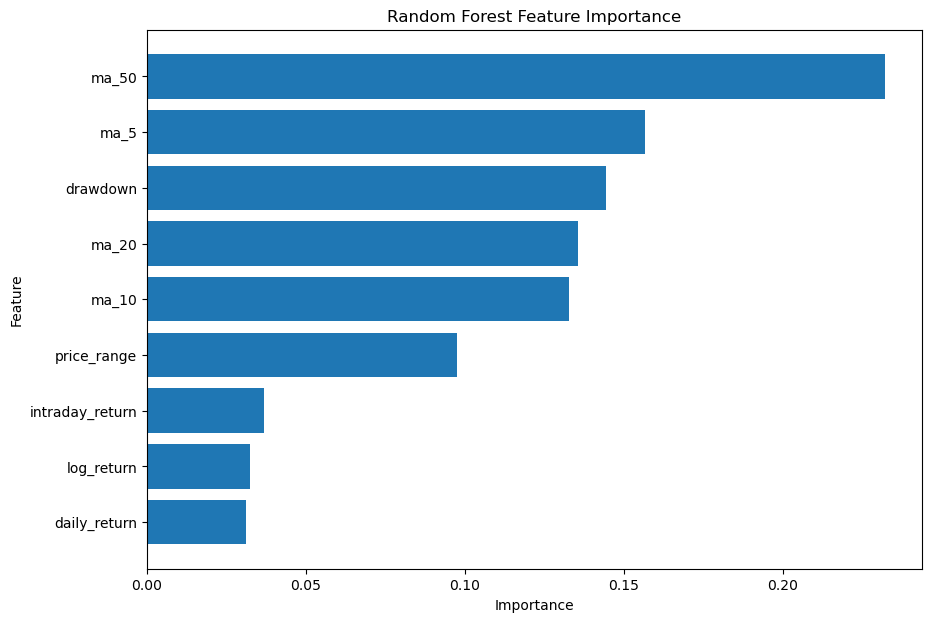

In [19]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [20]:
importance_path = "../data/processed/india_vix_random_forest_feature_importance.csv"

feature_importance.to_csv(
    importance_path,
    index=False
)

print("Feature importance saved successfully!")
print(importance_path)

Feature importance saved successfully!
../data/processed/india_vix_random_forest_feature_importance.csv


In [21]:
prediction_df = pd.DataFrame({
    "date": test_df["date"].values,
    "actual": y_test.values,
    "linear_regression": linear_predictions,
    "random_forest": rf_predictions
})

prediction_df.head(20)

,date,actual,linear_regression,random_forest
0,2024-10-11,0.319648,0.750822,0.561681
1,2024-10-14,0.477597,0.634144,0.671046
2,2024-10-15,0.516890,0.729848,0.743915
3,2024-10-16,0.499929,0.692901,0.741737
4,2024-10-17,0.691743,0.719809,0.711722
5,2024-10-18,0.651481,0.624867,0.712471
6,2024-10-21,0.652747,0.718103,0.701596
7,2024-10-22,0.573638,0.929514,0.817430
8,2024-10-23,0.738595,0.818786,0.635461
9,2024-10-24,0.561233,0.741546,0.664609


In [22]:
prediction_path = "../data/processed/india_vix_model_predictions.csv"

prediction_df.to_csv(
    prediction_path,
    index=False
)

print("Predictions saved successfully!")
print(prediction_path)

Predictions saved successfully!
../data/processed/india_vix_model_predictions.csv


In [23]:
print("INDIA VIX INITIAL MODEL EXPERIMENT")
print("----------------------------------")

print("\nTarget:")
print(target)

print("\nModels Tested:")
print("1. Baseline")
print("2. Linear Regression")
print("3. Random Forest")

print("\nEvaluation Metrics:")
print("1. MAE")
print("2. RMSE")

print("\nTraining Rows:", len(train_df))
print("Testing Rows:", len(test_df))

print("\nModel Results:")
print(results)

INDIA VIX INITIAL MODEL EXPERIMENT
----------------------------------

Target:
target_5d_volatility

Models Tested:
1. Baseline
2. Linear Regression
3. Random Forest

Evaluation Metrics:
1. MAE
2. RMSE

Training Rows: 1855
Testing Rows: 464

Model Results:
               Model       MAE      RMSE
0           Baseline  0.352424  0.557210
1  Linear Regression  0.330057  0.535504
2      Random Forest  0.332166  0.532913
